In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import os
import nibabel as nib

import sys
sys.path.append("/home/agustin/phd/synthesis/utils")

import util_freesurfer_segmentation as ufs



from cornucopia import (
    LoadTransform, RelabelTransform, RandomGMMGradientEchoTransform,
    IntensityTransform, QuantileTransform, MakeAffinePair, RandomAffineElasticTransform,
    RandomAffineTransform,
)

In [2]:
def show_image(img, seg, title=None):
    plt.figure(figsize=(10, 10))
    plt.subplot(1, 2, 1)
    plt.imshow(img.squeeze(), cmap='gray', interpolation='nearest')
    plt.axis('off')
    plt.title('MRI')
    plt.subplot(1, 2, 2)
    plt.imshow(seg.squeeze(), cmap='tab20', interpolation='nearest')
    plt.axis('off')
    plt.title('Labels')
    plt.show()

dat shape: torch.Size([1, 233, 197]), lab shape: torch.Size([1, 233, 197]), unique labels: tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16],
       dtype=torch.int32)


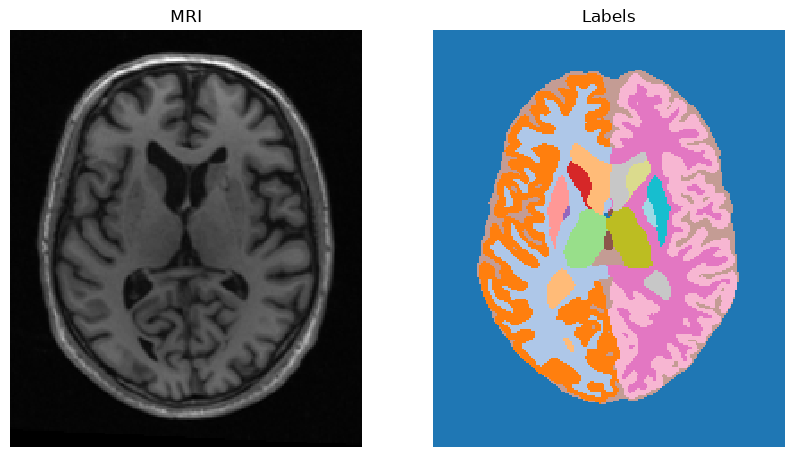

In [3]:
fname_img = "data/inputs/sub-ADNI002S0295_ses-m000_space-MNI_T1w.nii.gz"
fname_seg = "data/inputs/sub-ADNI002S0295_ses-m000_space-MNI_T1wdseg_synthsr.nii.gz"
# npz = np.load(fname)
# dat = torch.as_tensor(npz['vol'][:, :, 112]).T[None]
# lab = torch.as_tensor(npz['seg'][:, :, 112]).T[None]

seg = nib.load(fname_seg).get_fdata()
img = nib.load(fname_img).get_fdata()

thal = np.argwhere(np.isin(seg, [10, 49]))
cx, cy, cz = thal.mean(0).astype(int) if len(thal) else np.array(seg.shape) // 2

seg = ufs.merge_seg96_to_seg36(seg) #map to 0,1,2,3
dat = torch.as_tensor(np.flipud(img[:, :, cz].T).copy())[None]
lab = torch.as_tensor(np.flipud(seg[:, :, cz].T).copy())[None]

lab = RelabelTransform()(lab) #map to 0,1,2,3,...,N
# convert to int
lab = lab.to(torch.int32)
print(f"dat shape: {dat.shape}, lab shape: {lab.shape}, unique labels: {torch.unique(lab)}")

show_image(dat, lab, title='MRI and Labels')

# plt.figure(figsize=(10, 10))
# plt.subplot(1, 2, 1)
# plt.imshow(dat.squeeze(), cmap='gray', interpolation='nearest')
# plt.axis('off')
# plt.title('MRI')
# plt.subplot(1, 2, 2)
# plt.imshow(lab.squeeze(), cmap='tab20', interpolation='nearest')
# plt.axis('off')
# plt.title('Labels')
# plt.show()

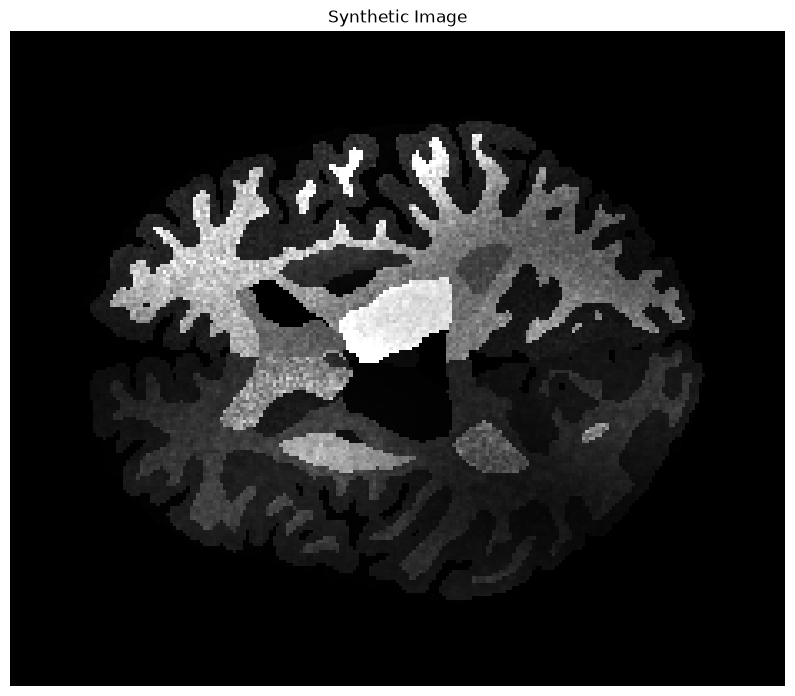

In [4]:
trf = RandomGMMGradientEchoTransform() + QuantileTransform()

img = trf(lab)

plt.figure(figsize=(10, 10))
plt.imshow(img.squeeze().T.flip(0), cmap='gray', interpolation='nearest', vmin=0, vmax=1)
plt.axis('off')
plt.title('Synthetic Image')
plt.show()

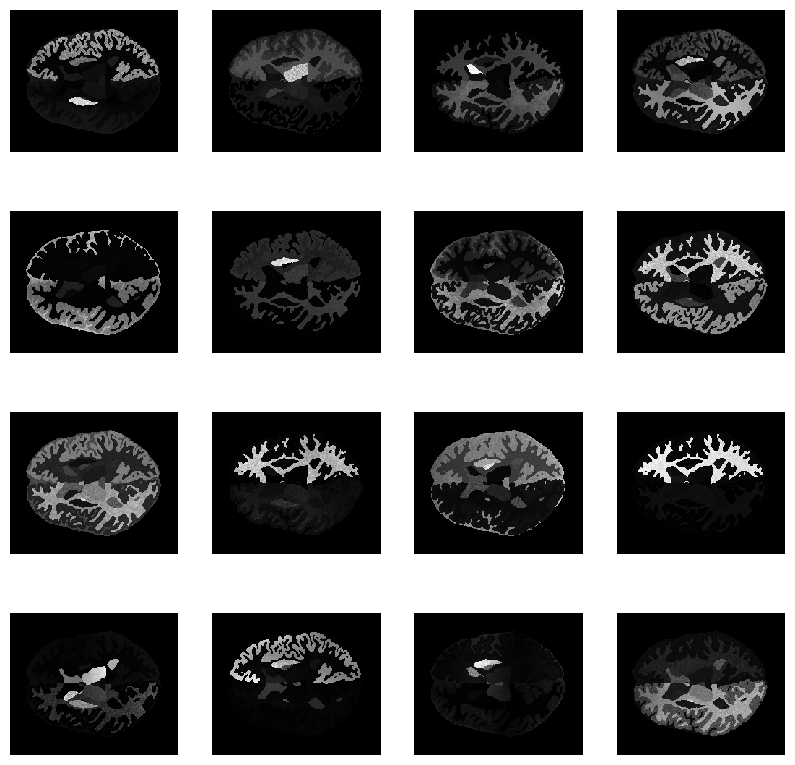

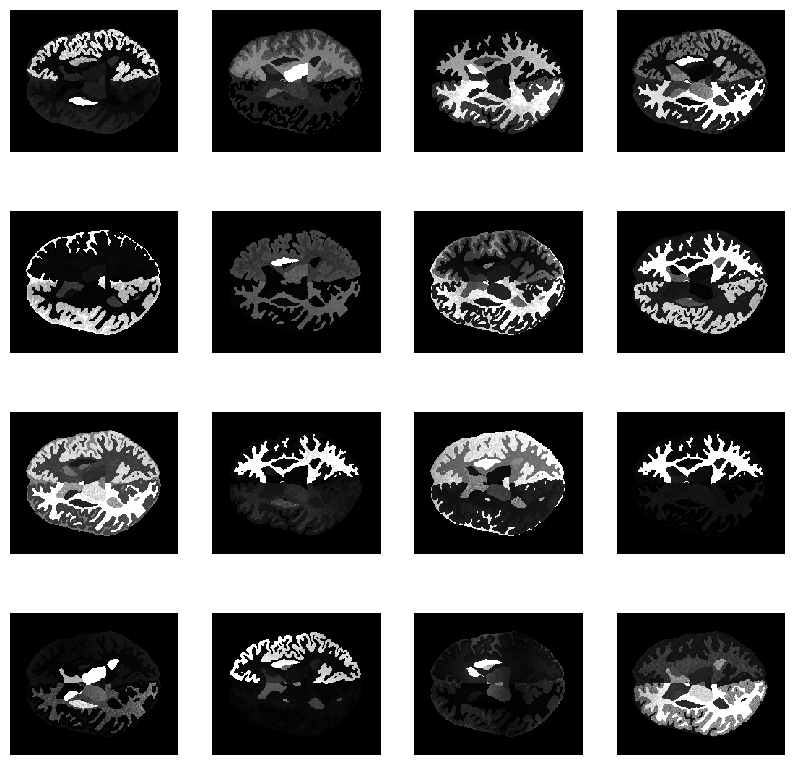

In [5]:
shape = [4, 4]
imgs = []

plt.figure(figsize=(10, 10))
for i in range(shape[0] * shape[1]):
    plt.subplot(*shape, i+1)
    imgs.append(trf(lab))
    plt.imshow(imgs[-1].squeeze().T.flip(0), cmap='gray', interpolation='nearest')
    plt.axis('off')
plt.show()


plt.figure(figsize=(10, 10))
for i in range(shape[0] * shape[1]):
    plt.subplot(*shape, i+1)
    plt.imshow(imgs[i].squeeze().T.flip(0), cmap='gray', interpolation='nearest', vmax=0.8)
    plt.axis('off')
plt.show()

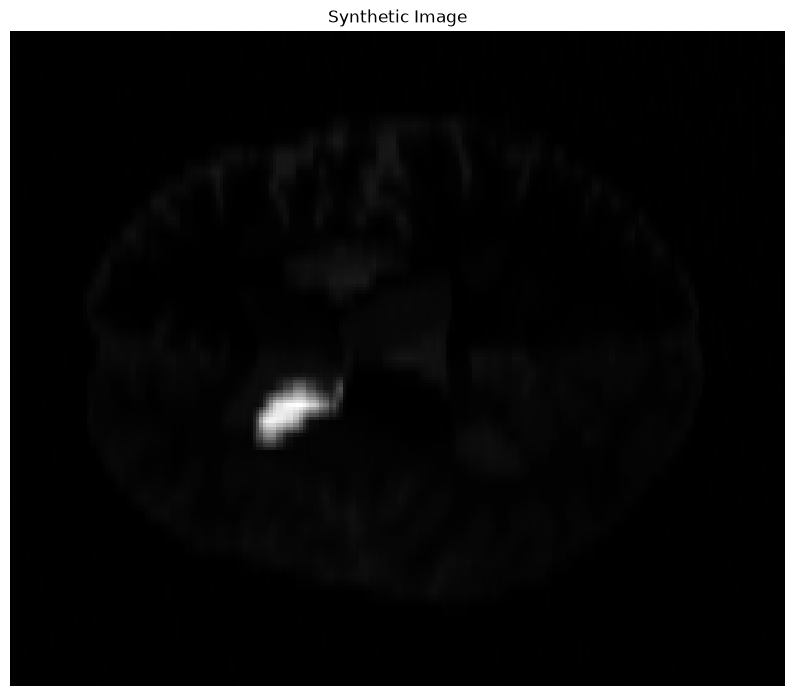

In [6]:
trf = (
    RandomGMMGradientEchoTransform() +
    QuantileTransform() +
    IntensityTransform()
)
img = trf(lab)

plt.figure(figsize=(10, 10))
plt.imshow(img.squeeze().T.flip(0), cmap='gray', interpolation='nearest')
plt.axis('off')
plt.title('Synthetic Image')
plt.show()

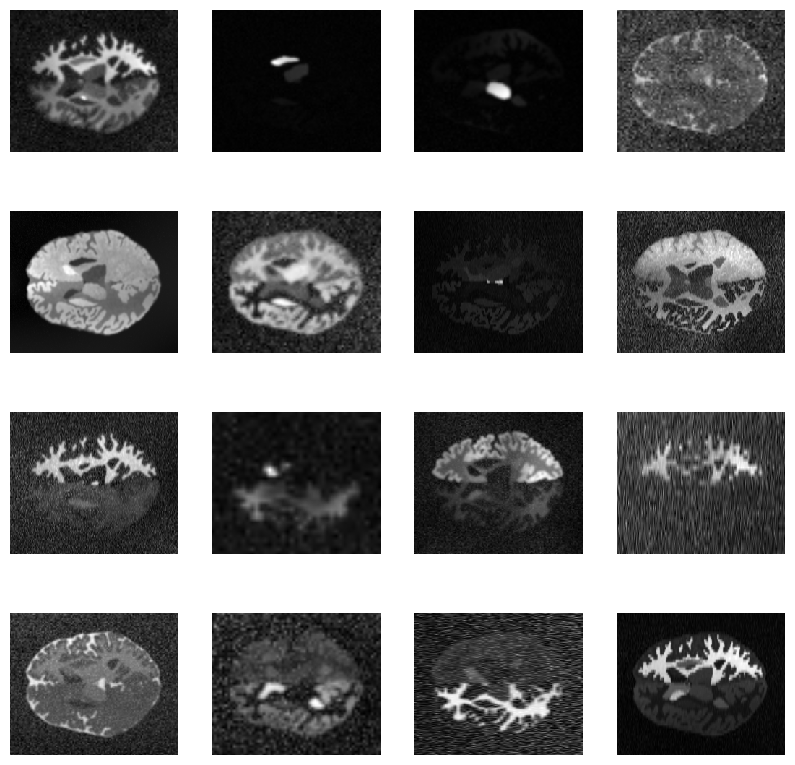

In [7]:
shape = [4, 4]
plt.figure(figsize=(10, 10))

for i in range(shape[0] * shape[1]):
    plt.subplot(*shape, i+1)
    img = trf(lab)
    plt.imshow(img.squeeze().T.flip(0), cmap='gray', interpolation='nearest')
    plt.axis('off')
plt.show()

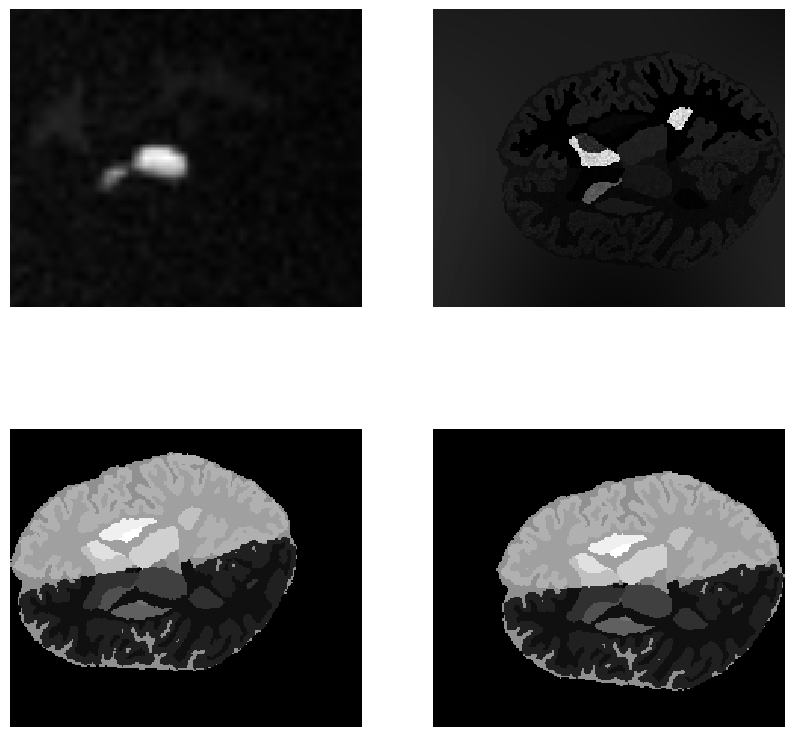

In [8]:
wrp = RandomAffineElasticTransform()
aff = MakeAffinePair(
    RandomAffineTransform(shears=0, zooms=0),
    returns=dict(left='left', right='right', flow='flow')
)
gre = RandomGMMGradientEchoTransform(
    returns=dict(label='input', image='output'), append=True, exclude='flow'
)
qtl = QuantileTransform(include=['left.image', 'right.image'])
aug = IntensityTransform(include=['left.image', 'right.image'])

trf = (wrp + aff + gre + qtl + aug)

out = trf(lab)
image_left = out['left.image']
image_right = out['right.image']
label_left = out['left.label']
label_right = out['right.label']
flow = out['flow']

plt.figure(figsize=(10, 10))
plt.subplot(2, 2, 1)
plt.imshow(image_left.squeeze().T.flip(0), cmap='gray', interpolation='nearest')
plt.axis('off')
plt.subplot(2, 2, 2)
plt.imshow(image_right.squeeze().T.flip(0), cmap='gray', interpolation='nearest')
plt.axis('off')
plt.subplot(2, 2, 3)
plt.imshow(label_left.squeeze().T.flip(0), cmap='gray', interpolation='nearest')
plt.axis('off')
plt.subplot(2, 2, 4)
plt.imshow(label_right.squeeze().T.flip(0), cmap='gray', interpolation='nearest')
plt.axis('off')
plt.show()